In [1]:
!pip install -q ultralytics roboflow opencv-python matplotlib

from roboflow import Roboflow
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os




[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

rf = Roboflow(api_key="Va0bafDgPi8D2KaHxm66")
project = rf.workspace("gfo-fc1de").project("fire-and-smoke-detector-yykya")
version = project.version(14)
dataset = version.download("yolov8")

print("Workspace:", "gfo-fc1de")
print("Project:", "fire-and-smoke-detector-yykya")
print("Version:", 14)
print("Dataset Location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...
Workspace: gfo-fc1de
Project: fire-and-smoke-detector-yykya
Version: 14
Dataset Location: d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\fire-and-smoke-detector-14


In [8]:
train_results = model.train(
    data=data_yaml_path,
    epochs=2,
    imgsz=320,
    batch=32,
    fraction=0.2,
    workers=0,
    project="runs_subtask1",
    name="fire_smoke_yolov8n",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.197  Python-3.14.4 torch-2.15.0+cpu CPU (13th Gen Intel Core i5-13450HX)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\fire and smoke detector.v14i.yolov8\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.2, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_d

Ultralytics 8.4.197  Python-3.14.4 torch-2.15.0+cpu CPU (13th Gen Intel Core i5-13450HX)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 297.6±101.8 MB/s, size: 49.5 KB)
val: Scanning D:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\fire and smoke detector.v14i.yolov8\valid\labels.cache... 1017 images, 105 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 1017/1017 266.6Mit/s 0.0s
val: D:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\fire and smoke detector.v14i.yolov8\valid\images\WaterMistFireDemonstration3447_png.rf.8b898bfa25fa838fbdea67cf21cd9556.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 64/64 2.6it/s 24.6s0.4ss
                   all       1016       1651      0.218      0.129     0.0829     0.0248
                  fire        835       1030      0.216      0.256      0.157     0.0475
     

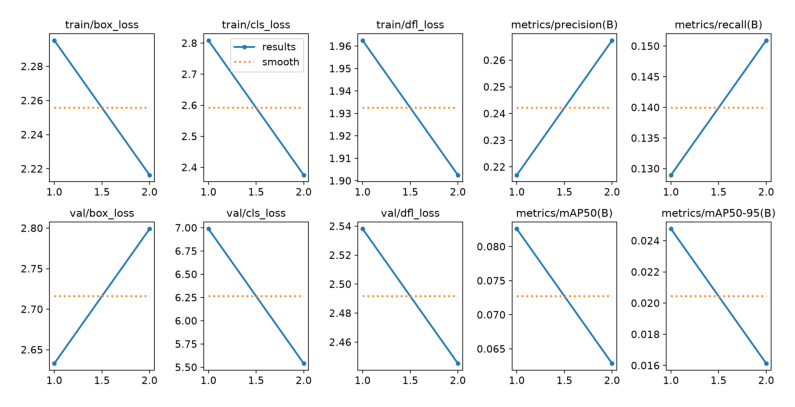

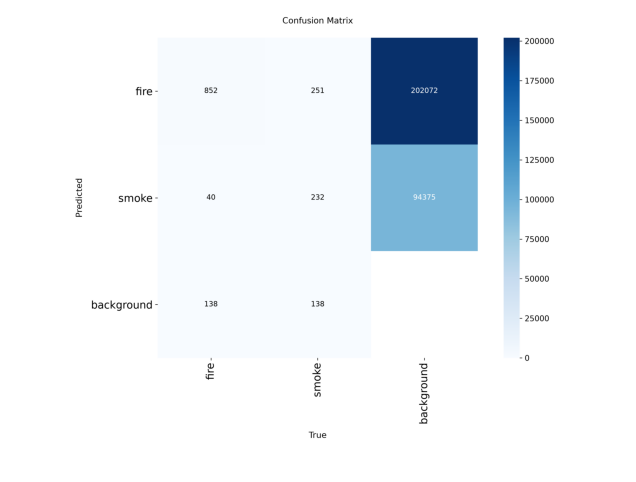

In [9]:


save_dir = str(train_results.save_dir)
best_pt = os.path.join(save_dir, "weights", "best.pt")
last_pt = os.path.join(save_dir, "weights", "last.pt")

val_metrics = YOLO(best_pt).val(data=data_yaml_path)

for name in ["results.png", "confusion_matrix.png"]:
  p = os.path.join(save_dir, name)
  if os.path.exists(p):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [12]:
trained_model = YOLO(best_pt)

results = trained_model.predict(
    source="sample_video.mp4",
    conf=0.25,
    save=True,
    project="runs_subtask1",
    name="video_prediction",
    exist_ok=True,
)


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/100) d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\sample_video.mp4: 256x320 4 fires, 47.4ms
video 1/1 (frame 2/100) d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\sample_video.mp4: 256x320 4 fires, 18.1ms
video 1/1 (frame 3/100) d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\sample_video.mp4: 256x320 3 fires, 20.1ms
video 1/1 (frame 4/100) d:\marwan\ROUTE AI&ML\ASSIGMENT\ASS.12\sample_video.mp4: 256x320 2 fires, 19.4ms
video 1/1 (frame 5/100) d:\marwan\ROUTE AI